<a href="https://colab.research.google.com/github/akhil7981/ML_LAB_2026-27/blob/main/ML2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import datetime

#### 1. Generate Synthetic Stock Data

Since no specific stock data was provided, we'll create a synthetic dataset that mimics daily stock prices (Open, High, Low, Close, Volume).

In [3]:
# Generate dates for the last 365 days
dates = [datetime.date.today() - datetime.timedelta(days=x) for x in range(365, 0, -1)]

# Generate synthetic stock data
np.random.seed(42)

# Base price trend
base_price = 100 + np.cumsum(np.random.randn(365))

# Open, High, Low, Close, Volume
open_price = base_price + np.random.uniform(-2, 2, 365)
high_price = open_price + np.random.uniform(0, 3, 365)
low_price = open_price - np.random.uniform(0, 3, 365)
close_price = open_price + np.random.uniform(-1, 1, 365)
volume = np.random.randint(100000, 1000000, 365)

data = pd.DataFrame({
    'Date': dates,
    'Open': open_price,
    'High': high_price,
    'Low': low_price,
    'Close': close_price,
    'Volume': volume
})

# Ensure 'Close' is always positive
data['Close'] = data['Close'].apply(lambda x: max(x, 1.0))

data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)

print("Synthetic Stock Data:")
display(data.head())

Synthetic Stock Data:


,Open,High,Low,Close,Volume
Date,,,,,
2025-08-07,99.391098,99.920258,97.142142,98.940710,169122
2025-08-08,102.211340,103.706443,101.821081,102.856569,771447
2025-08-09,99.054756,100.311533,96.779967,98.902233,673156
2025-08-10,104.408684,107.153221,104.334923,104.743783,743407
2025-08-11,100.467655,101.554836,100.401284,99.658725,516441


#### 2. Feature Engineering

We'll create a new feature: the 'Next Day Close' price, which will be our target variable. We will also use 'Open', 'High', 'Low', 'Volume', and the 'Previous Day Close' as features.

In [4]:
# Create 'Next Day Close' as the target variable
data['Next Day Close'] = data['Close'].shift(-1)

# Create 'Previous Day Close' as a feature
data['Previous Day Close'] = data['Close'].shift(1)

# Drop rows with NaN values (the last row for 'Next Day Close' and the first for 'Previous Day Close')
data.dropna(inplace=True)

print("Data with Engineered Features:")
display(data.head())

Data with Engineered Features:


,Open,High,Low,Close,Volume,Next Day Close,Previous Day Close
Date,,,,,,,
2025-08-08,102.211340,103.706443,101.821081,102.856569,771447,98.902233,98.940710
2025-08-09,99.054756,100.311533,96.779967,98.902233,673156,104.743783,102.856569
2025-08-10,104.408684,107.153221,104.334923,104.743783,743407,99.658725,98.902233
2025-08-11,100.467655,101.554836,100.401284,99.658725,516441,103.873169,104.743783
2025-08-12,103.625450,105.367215,102.654620,103.873169,981718,103.654431,99.658725


#### 3. Data Splitting

We'll split the data into features (X) and target (y), and then further divide them into training and testing sets. We'll use a time-series aware split, ensuring that our training data comes before our test data.

In [6]:
# Define features (X) and target (y)
X = data[['Open', 'High', 'Low', 'Volume', 'Previous Day Close']]
y = data['Next Day Close']

# Split data into training and testing sets (e.g., 80% train, 20% test)
split_ratio = 0.8
split_index = int(len(data) * split_ratio)

X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")

Training data shape: (290, 5)
Testing data shape: (73, 5)


#### 4. Model Training

We'll use Scikit-learn's `LinearRegression` model to train on our prepared training data.

In [7]:
# Initialize and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")
print(f"Model coefficients: {model.coef_}")
print(f"Model intercept: {model.intercept_}")

Linear Regression model trained successfully.
Model coefficients: [ 4.86530266e-01  1.40316931e-01 -1.48588041e-03 -1.14971872e-07
  3.08170667e-01]
Model intercept: 6.0689416245346735


#### 5. Prediction and Evaluation

Now, we'll make predictions on the test set and evaluate the model's performance using metrics like Mean Squared Error (MSE) and R-squared.

In [13]:
# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2): {r2:.2f}")

Mean Squared Error (MSE): 3.58
R-squared (R2): 0.69


#### Linear Regression Graph: Scatter Dots and Fit Line

This graph shows the actual values as scatter dots and the linear regression prediction as a straight line, illustrating the relationship between the features and the target variable.

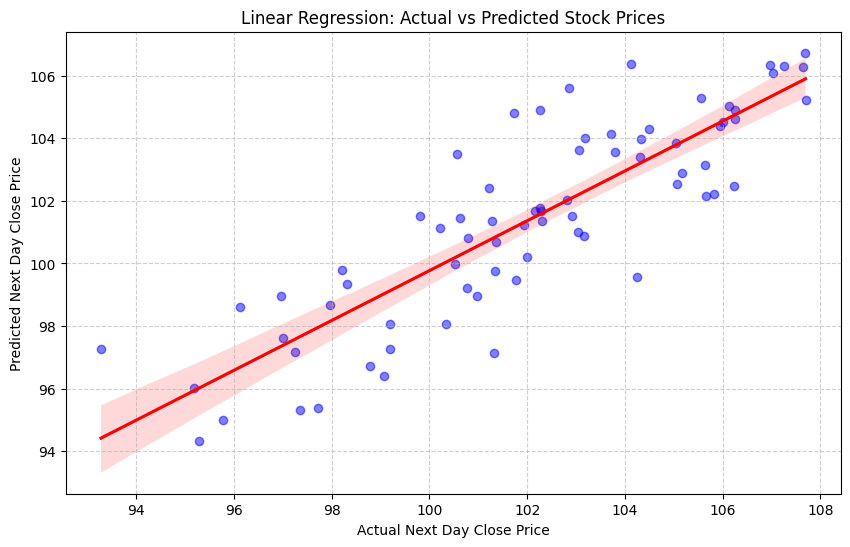

In [18]:
import seaborn as sns

# Creating the scatter plot with a regression line
plt.figure(figsize=(10, 6))
sns.regplot(x=y_test, y=y_pred, scatter_kws={'color': 'blue', 'alpha': 0.5}, line_kws={'color': 'red'})

plt.title('Linear Regression: Actual vs Predicted Stock Prices')
plt.xlabel('Actual Next Day Close Price')
plt.ylabel('Predicted Next Day Close Price')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()